# 2. El modelo

Este notebook muestra cómo está armado el modelo y si es confiable. El modelo se entrena con `uv run mmm fit`. Este notebook lee el resultado guardado en `artifacts/`.

In [1]:
import json

from mmm import plots
from mmm.cli import DIAGNOSTICS_PATH, MODEL_PATH

import arviz as az
from pymc_marketing.mmm import MMM

mmm =MMM.load(str(MODEL_PATH))
results = json.loads((plots.ROOT / "site" / "data" / "resultados.json").read_text(encoding="utf-8"))

## Priors

Un prior es lo que el modelo supone antes de ver los datos. El modelo usa los priors por defecto de PyMC-Marketing.

In [2]:
for name, prior in mmm.default_model_config.items():
    print(f"{name}: {prior}")

intercept: Prior("Normal", mu=0, sigma=2, dims=())
likelihood: Prior("Normal", sigma=Prior("HalfNormal", sigma=2, dims=()), dims="date")
gamma_control: Prior("Normal", mu=0, sigma=2, dims="control")
gamma_fourier: Prior("Laplace", mu=0, b=1, dims="fourier_mode")
adstock_alpha: Prior("Beta", alpha=1, beta=3, dims="channel")
saturation_lam: Prior("Gamma", alpha=3, beta=1, dims="channel")
saturation_beta: Prior("HalfNormal", sigma=2, dims="channel")


## Controles de calidad

`mmm fit` se detiene si hay divergencias, si el R-hat es 1,01 o más, o si el ESS es 400 o menos.

In [3]:
json.loads(DIAGNOSTICS_PATH.read_text(encoding="utf-8"))

{'divergences': 0,
 'max_rhat': 1.0022947406076754,
 'min_ess': 1049.4695053379019,
 'holdout_mape': 0.029128877197003727}

In [4]:
free = [rv.name for rv in mmm.model.free_RVs]
az.summary(mmm.idata["posterior"].to_dataset()[free]).round(3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept_contribution,-0.033,0.043,-0.1,0.036,1049,1374,1.00,0.0013,0.00079
adstock_alpha[tv_S],0.09,0.067,0.0092,0.21,6185,3723,1.00,0.00074,0.00089
adstock_alpha[ooh_S],0.428,0.21,0.082,0.76,6976,4751,1.00,0.0025,0.0018
adstock_alpha[print_S],0.169,0.144,0.011,0.44,7905,4444,1.00,0.0015,0.0021
adstock_alpha[facebook_S],0.198,0.163,0.015,0.51,9130,4200,1.00,0.0016,0.0022
adstock_alpha[search_S],0.358,0.228,0.036,0.74,5279,4707,1.00,0.0031,0.0018
saturation_lam[tv_S],5.84,1.82,3.1,8.9,4679,3550,1.00,0.026,0.027
saturation_lam[ooh_S],2.36,1.71,0.45,5.5,4567,3652,1.00,0.022,0.023
saturation_lam[print_S],2.27,1.47,0.48,5,3652,3235,1.00,0.022,0.018
saturation_lam[facebook_S],2.27,1.55,0.44,5.2,4660,3578,1.00,0.02,0.019


## Prueba con 12 semanas que el modelo no vio

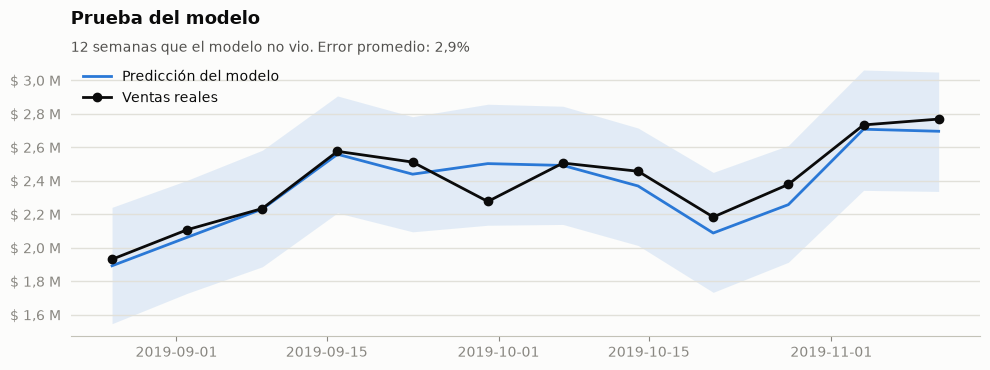

In [5]:
plots.plot_holdout(results);